#### Data Explore "New Car Registration by Make" from data.gov.sg

#### Take note from 2022 July onwards, the catogories of fuel-type is split into petrol-electric/(plug-in) and diesel-electric (plug-in)

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df_car = pd.read_csv("/home/eric/NTU_DSAI/Project_2/data_lta/Car_Regn_by_make_8_2026.csv")
df_coe = pd.read_csv("/home/eric/NTU_DSAI/Project_2/data_lta/coe_results_10_2026.csv")

print(df_car.tail())
print(df_coe.tail())

         month   make importer_type                  fuel_type  \
61978  2026-08  VOLVO           AMD            Petrol-Electric   
61979  2026-08  VOLVO           AMD  Petrol-Electric (Plug-In)   
61980  2026-08  VOLVO           AMD                   Electric   
61981  2026-08  XPENG           AMD                   Electric   
61982  2026-08  ZEEKR           AMD                   Electric   

             vehicle_type  number  
61978  Coupe/ Convertible     NaN  
61979  Coupe/ Convertible     NaN  
61980  Coupe/ Convertible     NaN  
61981  Coupe/ Convertible     NaN  
61982  Coupe/ Convertible     NaN  
        month  bidding_no vehicle_class  quota bids_success bids_received  \
1980  2026-10           1    Category A   1232        1,232         1,560   
1981  2026-10           1    Category B    945          938         1,126   
1982  2026-10           1    Category C    310          307           471   
1983  2026-10           1    Category D    530          522           599   
19

In [4]:
df_car.info()
df_coe.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61983 entries, 0 to 61982
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   month          61983 non-null  object 
 1   make           61983 non-null  object 
 2   importer_type  30828 non-null  object 
 3   fuel_type      61983 non-null  object 
 4   vehicle_type   61983 non-null  object 
 5   number         24634 non-null  float64
dtypes: float64(1), object(5)
memory usage: 2.8+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1985 entries, 0 to 1984
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   month          1985 non-null   object
 1   bidding_no     1985 non-null   int64 
 2   vehicle_class  1985 non-null   object
 3   quota          1985 non-null   int64 
 4   bids_success   1985 non-null   object
 5   bids_received  1985 non-null   object
 6   premium        1985 non-null   in

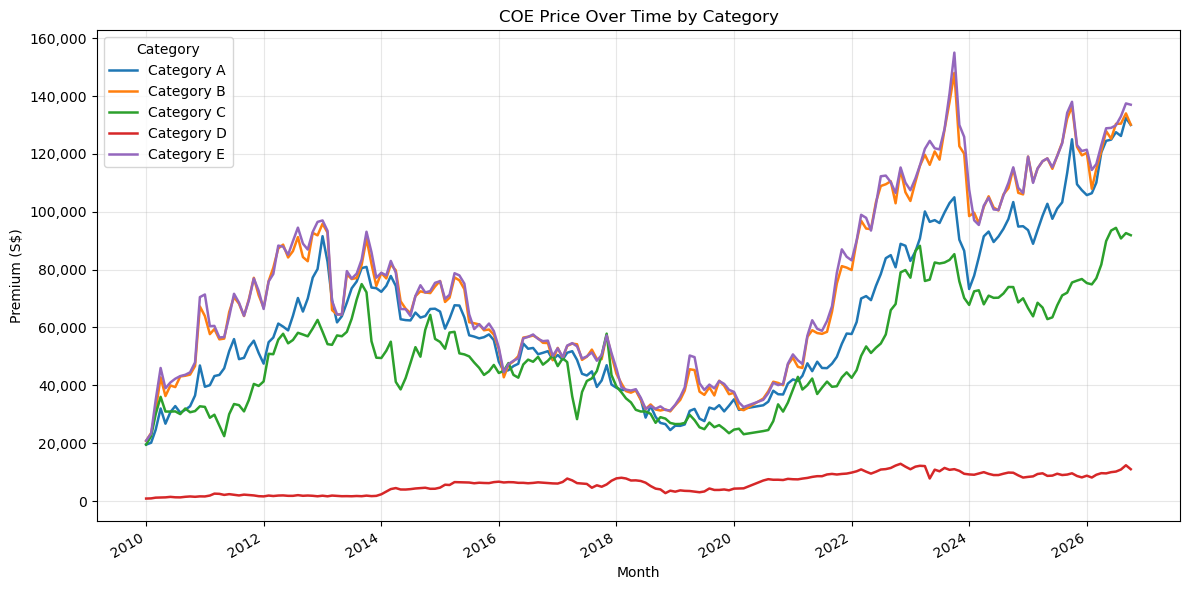

In [6]:
# 1. Convert month to datetime
df_coe["month"] = pd.to_datetime(df_coe["month"])

# 2. Average the bidding rounds per month, one column per category (A, B, C, D, E stay separate)
premium_by_month = (
    df_coe.groupby(["month", "vehicle_class"])["premium"]
    .mean()
    .unstack("vehicle_class")
)

# 3. Plot all categories as separate lines
fig, ax = plt.subplots(figsize=(12, 6))
premium_by_month.plot(ax=ax, linewidth=1.8)

ax.set_title("COE Price Over Time by Category")
ax.set_xlabel("Month")
ax.set_ylabel("Premium (S$)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.grid(True, alpha=0.3)
ax.legend(title="Category", loc="upper left")

plt.tight_layout()
plt.show()

In [7]:
# Count all fuel type from YR2022 to YR2024

count_fuel = df_car["fuel_type"].value_counts()

print("=== Vehicle Count by Fuel Type (2016-01 to 2025-05) ===")
print(count_fuel)


# 1. Clean the column: Remove commas (if any) and convert to numbers.
# Errors='coerce' will turn any non-numeric text (like words) into NaN (blank numbers)
df_coe['bids_success_num'] = pd.to_numeric(df_coe['bids_success'].astype(str).str.replace(',', ''), errors='coerce')

# 2. Group by vehicle class and sum the newly created numeric column
success_by_class = df_coe.groupby('vehicle_class')['bids_success_num'].sum()

print()

print("=== Successful Bids by Vehicle Class (in thousands) from 2010-01 to 2026-10 ===")
for vehicle_type, success_sum in success_by_class.items():
    # Convert individual sums to thousands
    success_in_thousands = success_sum / 1_000
    print(f"Vehicle Type: {vehicle_type} | Total Successful Bids: {success_in_thousands:.2f}M")

print("--------------------------------------------------")
# Convert grand total to thousands
grand_total_in_thousands = success_by_class.sum() / 1000
print(f"Grand Total: {grand_total_in_thousands:.2f}M")

=== Vehicle Count by Fuel Type (2016-01 to 2025-05) ===
Petrol                       29848
Electric                      9756
Petrol-Electric               7134
Diesel                        5947
Others                        5770
Petrol-Electric (Plug-In)     3450
Diesel-Electric                 60
Diesel-Electric (Plug-In)       18
Name: fuel_type, dtype: int64

=== Successful Bids by Vehicle Class (in thousands) from 2010-01 to 2026-10 ===
Vehicle Type: Category A | Total Successful Bids: 402.43M
Vehicle Type: Category B | Total Successful Bids: 304.04M
Vehicle Type: Category C | Total Successful Bids: 95.48M
Vehicle Type: Category D | Total Successful Bids: 191.27M
Vehicle Type: Category E | Total Successful Bids: 122.92M
--------------------------------------------------
Grand Total: 1116.15M


In [8]:
# Take note for EV, it includes "Petrol-Electric (Plug-In)", "Electric" and "Diesel-Electric (Plug-In)" 
# The classification of fuel type starts from YR2022 July onwards.
# Take note for COE-cars, it includes cat A, B, and E.

print(df_car["fuel_type"].unique())

print()

print(df_coe["vehicle_class"].unique())

['Petrol' 'Diesel' 'Others' 'Petrol-Electric' 'Petrol-Electric (Plug-In)'
 'Electric' 'Diesel-Electric (Plug-In)' 'Diesel-Electric']

['Category A' 'Category B' 'Category C' 'Category D' 'Category E']


In [9]:
# Define EV and Non-EV in SG

ev_df = df_car[
    df_car["fuel_type"].isin([
        "Electric",
        "Petrol-Electric (Plug-In)",
        "Diesel-Electric (Plug-In)"
    ])
]

n_ev_df = df_car[
    df_car["fuel_type"].isin([
        "Petrol",
        "Diesel",
        "Petrol-Electric",
        "Diesel-Electric",
        "Others"
    ])
]

print(ev_df)
print(n_ev_df)
print()

         month        make importer_type                  fuel_type  \
27918  2022-07        AUDI           NaN  Petrol-Electric (Plug-In)   
27919  2022-07        AUDI           NaN                   Electric   
27922  2022-07      B.M.W.           NaN  Petrol-Electric (Plug-In)   
27923  2022-07      B.M.W.           NaN                   Electric   
27925  2022-07     BLUECAR           NaN                   Electric   
...        ...         ...           ...                        ...   
61977  2026-08  VOLKSWAGEN           AMD                   Electric   
61979  2026-08       VOLVO           AMD  Petrol-Electric (Plug-In)   
61980  2026-08       VOLVO           AMD                   Electric   
61981  2026-08       XPENG           AMD                   Electric   
61982  2026-08       ZEEKR           AMD                   Electric   

             vehicle_type  number  
27918           Hatchback     NaN  
27919           Hatchback     2.0  
27922           Hatchback     NaN  
279

In [10]:
ev_by_month = (
     ev_df   # fuel_type: Electric, Petrol/Diesel-Electric (Plug-In)
    .groupby("month")["number"]
    .sum()
    .astype(int)
    .reset_index(name="count")
)
n_ev_by_month = (
     n_ev_df   # fuel_type: Petrol/Petrol-Electric, Diesel/Diesel-Electric and Others
    .groupby("month")["number"]
    .sum()
    .astype(int)
    .reset_index(name="count")
)

ev_non_ev_by_month = pd.merge(
    ev_by_month,
    n_ev_by_month,
    on="month"
).fillna(0)

print("                EV   &  Non-EV:")
print(ev_non_ev_by_month)

                EV   &  Non-EV:
      month  count_x  count_y
0   2022-07      311     2218
1   2022-08      297     2077
2   2022-09      443     1914
3   2022-10      408     1988
4   2022-11      367     1942
5   2022-12      423     1984
6   2023-01      289     1599
7   2023-02      260     1876
8   2023-03      312     2157
9   2023-04      332     1853
10  2023-05      394     1820
11  2023-06      451     1881
12  2023-07      504     1878
13  2023-08      605     1936
14  2023-09      562     1849
15  2023-10      457     1895
16  2023-11      581     1960
17  2023-12      987     3787
18  2024-01      646     1594
19  2024-02      763     1651
20  2024-03     1215     2293
21  2024-04     1225     2227
22  2024-05     1049     2139
23  2024-06     1217     2557
24  2024-07     1219     2698
25  2024-08     1433     2516
26  2024-09     1329     2796
27  2024-10     1200     2207
28  2024-11     1322     2284
29  2024-12     2040     3402
30  2025-01     1064     1639
31  2025

In [11]:
# Construct year column for analysis

df_car["month"] = pd.to_datetime(df_car["month"], format="%Y-%m")
df_car["year"] = df_car["month"].dt.year

df_coe["month"] = pd.to_datetime(df_coe["month"], format="%Y-%m")
df_coe["year"] = df_coe["month"].dt.year

In [12]:
# Check yearly

print(df_car.info())

print()

print(df_coe.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61983 entries, 0 to 61982
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   month          61983 non-null  datetime64[ns]
 1   make           61983 non-null  object        
 2   importer_type  30828 non-null  object        
 3   fuel_type      61983 non-null  object        
 4   vehicle_type   61983 non-null  object        
 5   number         24634 non-null  float64       
 6   year           61983 non-null  int64         
dtypes: datetime64[ns](1), float64(1), int64(1), object(4)
memory usage: 3.3+ MB
None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1985 entries, 0 to 1984
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   month             1985 non-null   datetime64[ns]
 1   bidding_no        1985 non-null   int64         
 2   vehicle_class     1

In [13]:
# Classify each row as EV or Non-EV
df_car["ev_category"] = df_car["fuel_type"].isin([
    "Electric",
    "Petrol-Electric (Plug-In)",
    "Diesel-Electric (Plug-In)"
]).map({True: "EV", False: "Non-EV"})

# Count EV and Non-EV registrations by year
ev_non_ev_by_year = (
    df_car.groupby(["year", "ev_category"])["number"]
      .sum()
      .unstack(fill_value=0)
      .reset_index()
)

print(ev_non_ev_by_year)

ev_category  year       EV   Non-EV
0            2016      0.0  87504.0
1            2017      0.0  91922.0
2            2018      0.0  80281.0
3            2019      0.0  72344.0
4            2020      0.0  44465.0
5            2021      0.0  45442.0
6            2022   2249.0  28690.0
7            2023   5734.0  24491.0
8            2024  14658.0  28364.0
9            2025  24602.0  28076.0
10           2026  24079.0  12567.0


In [14]:
# 1. Map vehicle classes to Car (combine Cat A, B & E) vs Non-Car
df_coe["coe_car"] = df_coe["vehicle_class"].isin(
    ["Category A", "Category B", "Category E"]
).map({True: "Car", False: "Non Car"})

# 2. Make sure bids_success is numeric (strip commas/spaces if present)
df_coe["bids_success"] = pd.to_numeric(
    df_coe["bids_success"].astype(str).str.replace(",", "").str.strip(),
    errors="coerce",
)

# 3. Filter for Cars, group by year, sum the bids, scale to thousands
result = (
    df_coe[df_coe["coe_car"] == "Car"]
    .groupby("year")["bids_success"]
    .sum()
    / 1000
)

# 4. Format to 1 decimal place with a 'K' suffix
formatted = result.round(1).astype(str) + "K"

print(formatted)

year
2010    41.2K
2011    30.1K
2012    27.8K
2013    22.5K
2014    29.1K
2015    60.9K
2016    89.9K
2017    88.9K
2018    83.0K
2019    68.6K
2020    43.5K
2021    44.7K
2022    29.2K
2023    29.6K
2024    43.0K
2025    52.9K
2026    44.6K
Name: bids_success, dtype: object


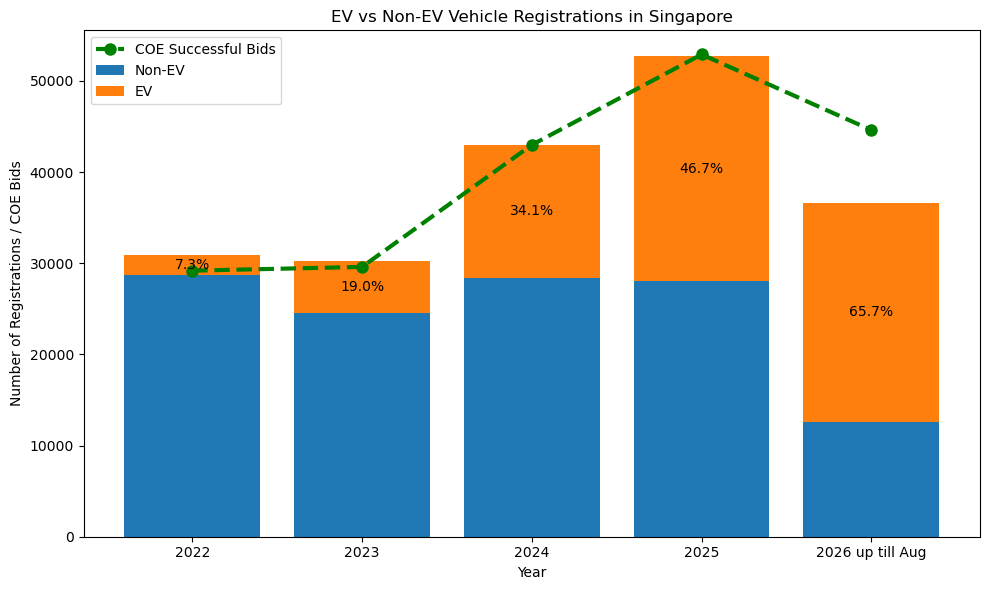

In [15]:
# Assume df_coe is already loaded
# 1. Map vehicle classes to Car (combine Cat A, B & E) vs Non-Car
df_coe["coe_car"] = (
    df_coe["vehicle_class"]
    .isin(["Category A", "Category B", "Category E"])
    .map({True: "Car", False: "Non-Car"})
)

# 2. Filter for Cars, group by year, sum the bids, and scale to thousands
result_coe = (
    df_coe[df_coe["coe_car"] == "Car"]
    .groupby("year")["bids_success"]
    .sum()
    )

# --- EV vs Non-EV Plot Integration ---
plot_data = ev_non_ev_by_year[ev_non_ev_by_year["year"] >= 2022].copy()

# Merge or align coe_car total by year if you want to display it or plot it
plot_data["coe_car"] = plot_data["year"].map(result_coe)

years = plot_data["year"]
non_ev = plot_data["Non-EV"]
ev = plot_data["EV"]

plt.figure(figsize=(10, 6))

# Non-EV
plt.bar(years, non_ev, label="Non-EV")
# EV stacked on top
plt.bar(years, ev, bottom=non_ev, label="EV")

# Optional: Plot COE Car total as a line or scatter for comparison
if "coe_car" in plot_data:
  plt.plot(
      years,
      plot_data["coe_car"],
      color="green",
      marker="o",
      linestyle="--",
      linewidth=3,      # default is 1.5; increase for a thicker line
      markersize=8,     # optional: bigger markers to match
      label="COE Successful Bids",
  )

# Add EV percentage
for i in range(len(plot_data)):
  total = non_ev.iloc[i] + ev.iloc[i]
  ev_pct = ev.iloc[i] / total * 100
  plt.text(
      years.iloc[i],
      non_ev.iloc[i] + ev.iloc[i] / 2,
      f"{ev_pct:.1f}%",
      ha="center",
      va="center",
      fontsize=10,
  )

# Change only the displayed labels
labels = [
    "2026 up till Aug" if y == 2026 else str(y) for y in years
]  # fixed variable name collision
plt.xticks(years, labels)
plt.xlabel("Year")
plt.ylabel("Number of Registrations / COE Bids")
plt.title("EV vs Non-EV Vehicle Registrations in Singapore")
plt.legend()
plt.tight_layout()
plt.show()


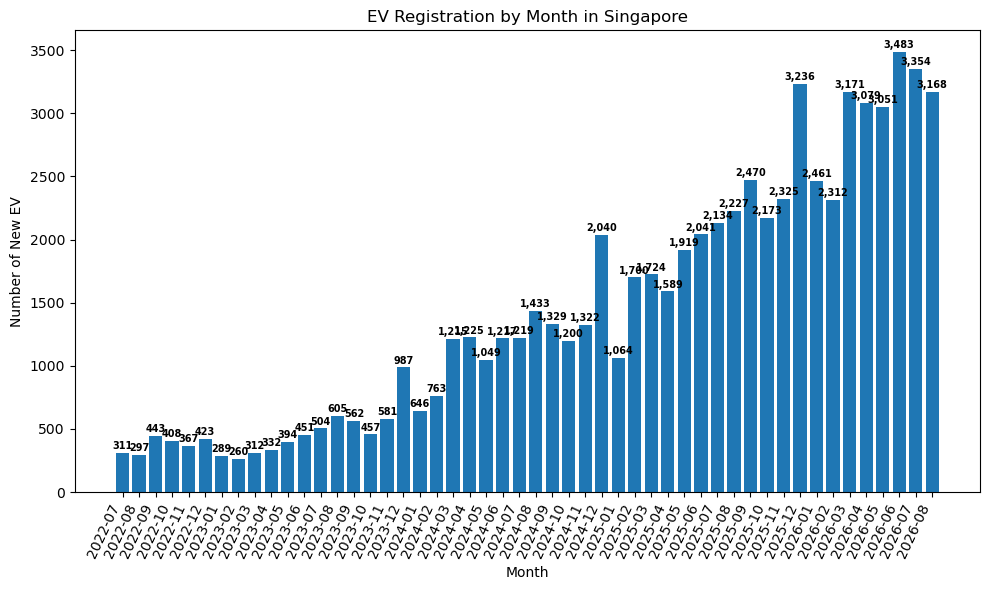

In [16]:
# Plot the bar chart

import matplotlib.pyplot as plt

ev = (
    ev_df
    .groupby("month")["number"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    ev["month"].astype(str),
    ev["number"]
)

plt.xlabel("Month")
plt.ylabel("Number of New EV")
plt.title("EV Registration by Month in Singapore")

# Add values on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height +15,
        f"{int(height):,}",
        ha="center",
        va="bottom",
        fontsize=7,
        color='black',
        fontweight='bold')
    plt.xticks(rotation=65, ha='right')

plt.tight_layout()
plt.show()

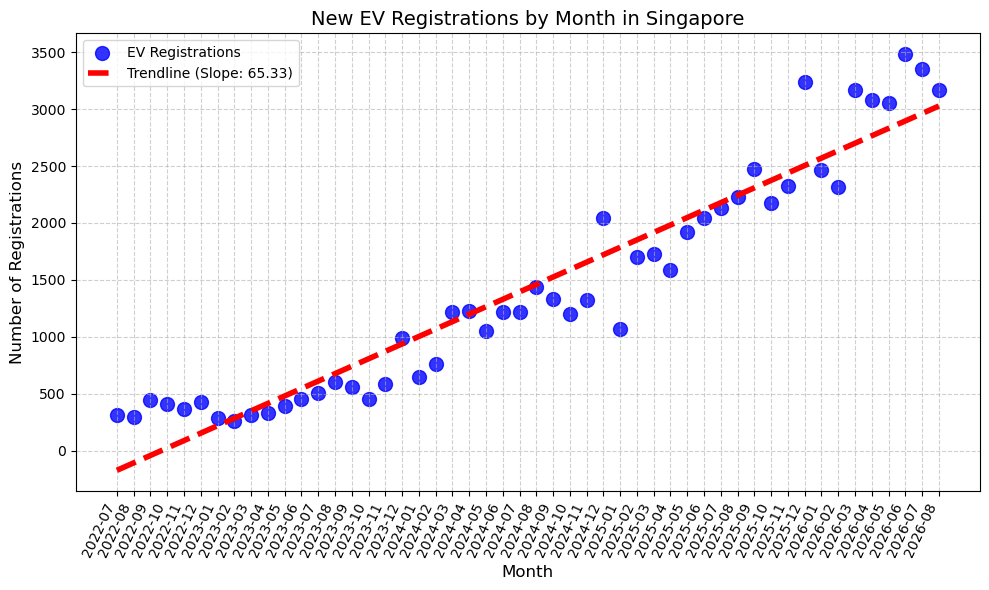

In [17]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 6))

# 1. Extract X and Y data
x_data = ev_by_month["month"]
y_data = ev_by_month["count"]

# 2. Create numerical indices for the X-axis calculation
x_indices = np.arange(len(x_data))

# 3. Calculate the linear trendline (degree 1 polynomial: y = mx + c)
slope, intercept = np.polyfit(x_indices, y_data, 1)
trendline = slope * x_indices + intercept

# Plot EV scatter points
plt.scatter(
    x_data, y_data, 
    color="blue", label="EV Registrations", s=100, alpha=0.8
)

# 4. Plot the linear line
plt.plot(
    x_data, trendline, 
    color="red", linestyle="--", linewidth=4, 
    label=f"Trendline (Slope: {slope:.2f})")

plt.title("New EV Registrations by Month in Singapore", fontsize=14)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Number of Registrations", fontsize=12)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.xticks(rotation=65, ha='right')

plt.tight_layout() # Prevents cut-off rotated X-axis labels
plt.show()


In [18]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [19]:
from sklearn.linear_model import LinearRegression

# -----------------------------------
# 1. Filter data from 2022 onwards
# -----------------------------------

plot_data = ev_non_ev_by_year[
    ev_non_ev_by_year["year"] >= 2022
].copy()

# -----------------------------------
# 2. Annualize 2026
# -----------------------------------

# 2026 contains only first 8 months
mask_2026 = plot_data["year"] == 2026

plot_data.loc[mask_2026, "EV"] = (
    plot_data.loc[mask_2026, "EV"] / 8 * 12
)

plot_data.loc[mask_2026, "Non-EV"] = (
    plot_data.loc[mask_2026, "Non-EV"] / 8 * 12
)

# -----------------------------------
# 3. Forecast 2026–2030
# -----------------------------------

forecast_years = np.arange(2026, 2031)

model_ev = LinearRegression()
model_non_ev = LinearRegression()

X = plot_data[["year"]]

model_ev.fit(X, plot_data["EV"])
model_non_ev.fit(X, plot_data["Non-EV"])

ev_forecast = model_ev.predict(
    forecast_years.reshape(-1, 1)
)

non_ev_forecast = model_non_ev.predict(
    forecast_years.reshape(-1, 1)
)

# Prevent negative predictions
ev_forecast = np.maximum(ev_forecast, 0)
non_ev_forecast = np.maximum(non_ev_forecast, 0)

# -----------------------------------
# 4. Create forecast dataframe
# -----------------------------------

forecast_df = pd.DataFrame({
    "year": forecast_years,
    "EV": ev_forecast.round().astype(int),
    "Non-EV": non_ev_forecast.round().astype(int)
})

# Calculate EV percentage (Forecast)
forecast_df["EV_Percentage"] = (
    forecast_df["EV"] /
    (forecast_df["EV"] + forecast_df["Non-EV"]) * 100
)

# Calculate EV percentage (Actual)
ev_non_ev_by_year["EV_p"] = (
    ev_non_ev_by_year["EV"] /
    (ev_non_ev_by_year["EV"] + ev_non_ev_by_year["Non-EV"]) * 100
)

print(ev_non_ev_by_year)  # Actual

print()

print(forecast_df)   # Forecast

ev_category  year       EV   Non-EV       EV_p
0            2016      0.0  87504.0   0.000000
1            2017      0.0  91922.0   0.000000
2            2018      0.0  80281.0   0.000000
3            2019      0.0  72344.0   0.000000
4            2020      0.0  44465.0   0.000000
5            2021      0.0  45442.0   0.000000
6            2022   2249.0  28690.0   7.269143
7            2023   5734.0  24491.0  18.971050
8            2024  14658.0  28364.0  34.070940
9            2025  24602.0  28076.0  46.702608
10           2026  24079.0  12567.0  65.707035

   year     EV  Non-EV  EV_Percentage
0  2026  33994   22475      60.199401
1  2027  42654   20866      67.150504
2  2028  51315   19257      72.712974
3  2029  59976   17647      77.265759
4  2030  68636   16038      81.059121


/home/eric/miniconda3/envs/pds/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/home/eric/miniconda3/envs/pds/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [20]:
# Calculate EV percentage
forecast_df["EV_Percentage"] = (
    forecast_df["EV"] /
    (forecast_df["EV"] + forecast_df["Non-EV"]) * 100
)

print(forecast_df)

   year     EV  Non-EV  EV_Percentage
0  2026  33994   22475      60.199401
1  2027  42654   20866      67.150504
2  2028  51315   19257      72.712974
3  2029  59976   17647      77.265759
4  2030  68636   16038      81.059121


### Forecast full year 2026, 2027, 2028, 2029 and 2030 by using Linear Regression with lag(10) or 10-years time series model. Follow the fact that a COE can last for 10 years.

      quota bids_success
year                    
2010  41.9K        41.2K
2011  30.8K        30.1K
2012  28.3K        27.8K
2013  23.0K        22.5K
2014  29.5K        29.1K
2015  61.4K        60.9K
2016  91.3K        89.9K
2017  89.6K        88.9K
2018  83.7K        83.0K
2019  69.3K        68.6K
2020  44.0K        43.5K
2021  45.2K        44.7K
2022  29.5K        29.2K
2023  30.1K        29.6K
2024  43.7K        43.0K
2025  53.5K        52.9K
2026  45.2K        44.6K
   year  coe_car    total       EV   Non-EV
0  2026  66912.0  64228.0  43122.0  21106.0
1  2027  67092.0  64401.0  52515.0  11886.0
2  2028  64138.0  61566.0  55732.0   5833.0
3  2029  56978.0  54693.0  52168.0   2525.0
4  2030  44493.0  42708.0  41773.0    935.0


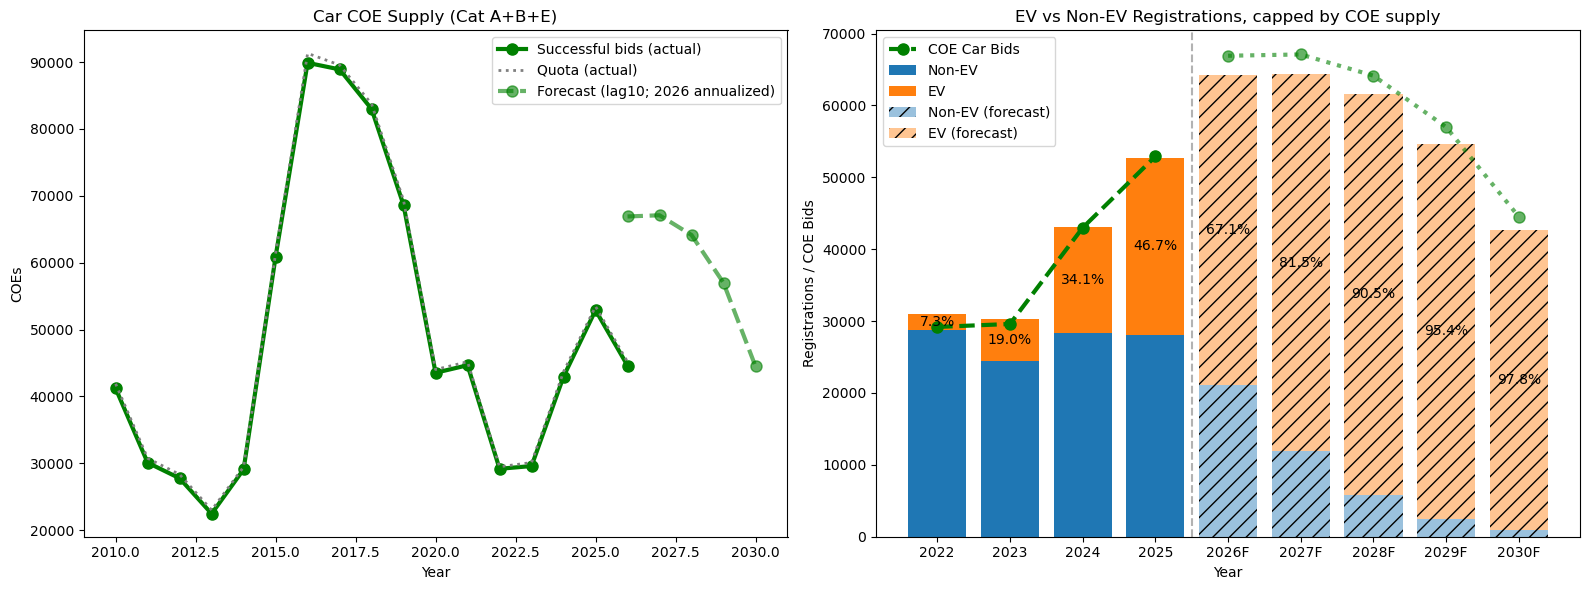

In [21]:
from sklearn.linear_model import LinearRegression
from scipy.special import logit, expit

# ---------- Settings ----------
MONTHS_2026 = 8          # data runs Jan-Aug 2026
SCENARIO = "lag10"       # "lag10" (10-year expiry wave) or "flat" (recent average)
CAR_CATS = ["Category A", "Category B", "Category E"]
FC_YEARS = np.arange(2026, 2031)

# ---------- 1. COE supply: Cat A + B + E, by year ----------
cars = df_coe[df_coe["vehicle_class"].isin(CAR_CATS)]
coe = cars.groupby("year").agg(quota=("quota", "sum"),
                               bids_success=("bids_success", "sum")).astype(float)
print((coe / 1000).round(1).astype(str) + "K")   # quota vs successful bids

# Annualize partial 2026
coe_full = coe.copy()
coe_full.loc[2026] = coe_full.loc[2026] * 12 / MONTHS_2026

# ---------- 2. Forecast car COE supply 2026-2030 ----------
s = coe_full["bids_success"]

if SCENARIO == "lag10":
    # successful bids this year vs successful bids 10 years earlier
    tr = pd.DataFrame({"y": s, "x": s.shift(10)}).dropna()
    lag_model = LinearRegression().fit(tr[["x"]], tr["y"])
    x_fc = np.array([s.loc[y - 10] for y in FC_YEARS]).reshape(-1, 1)
    coe_fc = pd.Series(np.clip(lag_model.predict(pd.DataFrame(x_fc, columns=["x"])), 0, None),
                       index=FC_YEARS)
else:
    coe_fc = pd.Series(s.loc[2023:2025].mean(), index=FC_YEARS)  # flat at 2023-25 average

coe_fc.loc[2026] = s.loc[2026]   # 2026: use annualized actual instead of model

# ---------- 3. Registrations: total from COE supply, split by EV share ----------
reg = ev_non_ev_by_year[ev_non_ev_by_year["year"] >= 2022].set_index("year")[["Non-EV", "EV"]].astype(float)
reg["total"] = reg["Non-EV"] + reg["EV"]
reg["ev_share"] = reg["EV"] / reg["total"]

# registrations per successful COE bid (2026 partial in both, so the ratio stays valid)
ratio = (reg["total"] / coe.loc[reg.index, "bids_success"]).loc[2023:].mean()

# logistic trend on EV share, so it can never exceed 100%
share_model = LinearRegression().fit(reg.index.values.reshape(-1, 1), logit(reg["ev_share"]))
ev_share_fc = expit(share_model.predict(FC_YEARS.reshape(-1, 1)))

fc = pd.DataFrame({"year": FC_YEARS, "coe_car": coe_fc.values})
fc["total"] = fc["coe_car"] * ratio
fc["EV"] = fc["total"] * ev_share_fc
fc["Non-EV"] = fc["total"] - fc["EV"]
print(fc.round(0))

# ---------- 4. Plot ----------
act = reg.loc[reg.index <= 2025].reset_index()
act["coe_car"] = act["year"].map(coe["bids_success"])

fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Left: car COE supply history and forecast
ax[0].plot(coe.index, coe["bids_success"], color="green", marker="o", lw=3, ms=8, label="Successful bids (actual)")
ax[0].plot(coe.index, coe["quota"], color="grey", ls=":", lw=2, label="Quota (actual)")
ax[0].plot(fc["year"], fc["coe_car"], color="green", ls="--", marker="o", lw=3, ms=8, alpha=0.6,
           label=f"Forecast ({SCENARIO}; 2026 annualized)")
ax[0].set_title("Car COE Supply (Cat A+B+E)")
ax[0].set_xlabel("Year"); ax[0].set_ylabel("COEs"); ax[0].legend()

# Right: EV vs Non-EV
ax[1].bar(act["year"], act["Non-EV"], color="tab:blue", label="Non-EV")
ax[1].bar(act["year"], act["EV"], bottom=act["Non-EV"], color="tab:orange", label="EV")
ax[1].bar(fc["year"], fc["Non-EV"], color="tab:blue", alpha=0.45, hatch="//", label="Non-EV (forecast)")
ax[1].bar(fc["year"], fc["EV"], bottom=fc["Non-EV"], color="tab:orange", alpha=0.45, hatch="//", label="EV (forecast)")
ax[1].plot(act["year"], act["coe_car"], color="green", marker="o", ls="--", lw=3, ms=8, label="COE Car Bids")
ax[1].plot(fc["year"], fc["coe_car"], color="green", marker="o", ls=":", lw=3, ms=8, alpha=0.6)

for df in (act.assign(t=act["Non-EV"] + act["EV"]), fc.assign(t=fc["total"])):
    for _, r in df.iterrows():
        ax[1].text(r["year"], r["Non-EV"] + r["EV"] / 2, f"{r['EV'] / r['t'] * 100:.1f}%",
                   ha="center", va="center", fontsize=10)

yrs = list(act["year"]) + list(fc["year"])
ax[1].set_xticks(yrs)
ax[1].set_xticklabels([str(int(y)) for y in act["year"]] + [f"{y}F" for y in fc["year"]])
ax[1].axvline(2025.5, color="grey", ls="--", alpha=0.6)
ax[1].set_title("EV vs Non-EV Registrations, capped by COE supply")
ax[1].set_xlabel("Year"); ax[1].set_ylabel("Registrations / COE Bids"); ax[1].legend()

plt.tight_layout()
plt.show()